# 01 — Exploration des données Olist

**Question posée à ce stade :** ces données permettent-elles de faire du pricing ?

Faire du pricing suppose trois choses, et une seule manque suffit à arrêter le projet :

1. observer une **quantité vendue** (la demande) ;
2. observer un **prix** qui varie ;
3. que la variation de prix soit **exploitable**, c'est-à-dire attribuable à une
   décision et non à un changement de produit.

Ce notebook vérifie les points 1 et 2. Le point 3 — le plus difficile — est
traité dans le notebook 02.

> **Note sur `data/raw/dynamic_pricing.csv`.** Le dossier contient aussi un jeu
> VTC synthétique. Il a été écarté : il donne un *coût de course* par
> observation, jamais un volume. Sans quantité, pas de courbe de demande, donc
> pas d'optimisation de prix — seulement une régression de prix. Les notebooks
> qui l'exploraient sont conservés dans `notebooks/_archive/`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

## 1. Les tables et leur rôle

Olist est une marketplace brésilienne. Le schéma est en flocon : les commandes
d'un côté, les articles de l'autre, les produits et vendeurs en dimensions.

In [2]:
from optimization_pricing.dataset import load_raw_tables

tables = load_raw_tables()

inventaire = pd.DataFrame(
    [
        {"table": nom, "lignes": len(df), "colonnes": df.shape[1]}
        for nom, df in tables.items()
    ]
).sort_values("lignes", ascending=False)
inventaire

2026-08-20 10:32:22.273 | INFO     | optimization_pricing.dataset:load_raw_tables:52 - Chargement des tables Olist brutes...


2026-08-20 10:32:23.477 | INFO     | optimization_pricing.dataset:load_raw_tables:63 - orders=(99441, 8) items=(112650, 7) products=(32951, 9) reviews=(99224, 7) payments=(103886, 5)


,table,lignes,colonnes
1,items,112650,7
5,payments,103886,5
0,orders,99441,8
4,reviews,99224,7
2,products,32951,9
3,sellers,3095,4
6,translation,71,2


In [3]:
orders, items = tables["orders"], tables["items"]
print("Statuts de commande :")
print(orders["order_status"].value_counts())
print()
print("Période couverte :", orders["order_purchase_timestamp"].min(), "->", orders["order_purchase_timestamp"].max())

Statuts de commande :
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Période couverte : 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


### Décision de nettoyage n°1 : ne garder que les commandes livrées

`canceled` et `unavailable` sont de la **demande non servie**. Les compter
comme des ventes gonflerait le volume et, pire, biaiserait le prix moyen : les
annulations ne sont pas réparties au hasard entre les gammes de prix.

C'est ~3 % des commandes, mais la propreté du signal prime sur le volume.

In [4]:
livrees = orders["order_status"].eq("delivered")
print(f"Commandes livrees : {livrees.sum():,} / {len(orders):,} ({livrees.mean():.1%})")
print(f"Ecartees          : {(~livrees).sum():,}")

Commandes livrees : 96,478 / 99,441 (97.0%)
Ecartees          : 2,963


## 2. Y a-t-il un prix, et varie-t-il ?

Le prix est au niveau de la **ligne de commande** (`order_items.price`) : c'est
le prix effectivement payé, pas un prix catalogue. C'est exactement ce qu'il
faut — un prix catalogue jamais appliqué ne renseigne sur aucune demande.

count   112,650.000
mean        120.654
std         183.634
min           0.850
25%          39.900
50%          74.990
75%         134.900
max       6,735.000
Name: price, dtype: float64


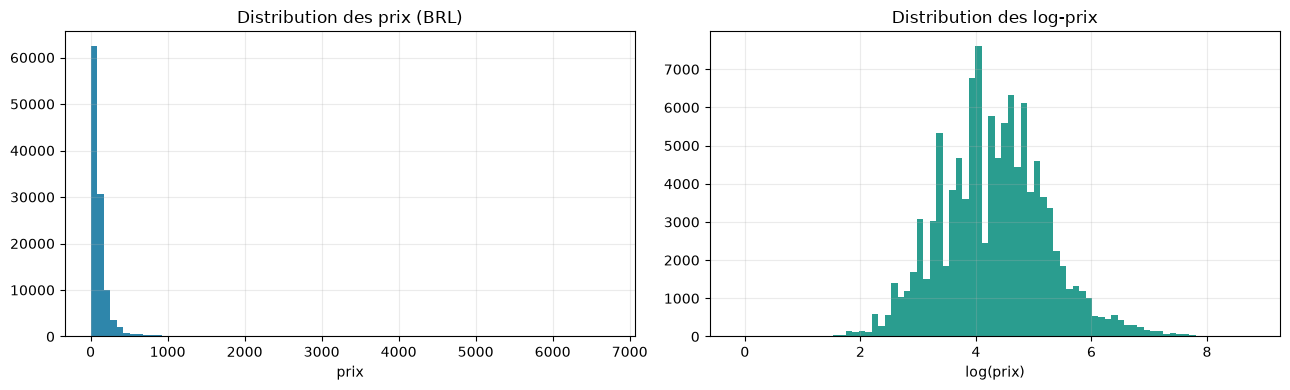

In [5]:
print(items["price"].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(items["price"], bins=80, color="#2E86AB")
axes[0].set_title("Distribution des prix (BRL)")
axes[0].set_xlabel("prix")

axes[1].hist(np.log(items["price"]), bins=80, color="#2A9D8F")
axes[1].set_title("Distribution des log-prix")
axes[1].set_xlabel("log(prix)")
plt.tight_layout()
plt.show()

La distribution brute est très asymétrique, la version log est quasi normale.
**C'est la première justification du modèle log-log** : en log, la relation
prix-demande devient linéaire et son coefficient *est* l'élasticité.

La queue droite contient des valeurs extrêmes (>99.5e percentile) qui, une fois
agrégées, feraient exploser un prix moyen de cellule. On les écrête.

In [6]:
seuil = items["price"].quantile(0.995)
extremes = items.loc[items["price"] > seuil]
print(f"Seuil d'ecretage (99.5e pct) : {seuil:,.0f} BRL")
print(f"Lignes ecretees : {len(extremes):,} ({len(extremes) / len(items):.2%})")
print(f"Part du CA concernee : {extremes['price'].sum() / items['price'].sum():.2%}")

Seuil d'ecretage (99.5e pct) : 1,218 BRL
Lignes ecretees : 564 (0.50%)
Part du CA concernee : 7.55%


## 3. Où se trouve la quantité ?

Il n'y a pas de colonne « quantité vendue » : chaque ligne est **un article**.
La demande se construit donc par comptage, ce qui impose de choisir une maille
d'agrégation — le sujet du notebook 02.

Regardons d'abord combien d'exemplaires se vend un produit typique.

In [7]:
ventes_par_produit = items.groupby("product_id").size()

print(ventes_par_produit.describe())
print()
for seuil_v in (1, 2, 5, 10, 30):
    part = (ventes_par_produit <= seuil_v).mean()
    print(f"produits vendus <= {seuil_v:>2} fois sur 2 ans : {part:6.1%}")

count   32,951.000
mean         3.419
std         10.620
min          1.000
25%          1.000
50%          1.000
75%          3.000
max        527.000
dtype: float64

produits vendus <=  1 fois sur 2 ans :  55.0%
produits vendus <=  2 fois sur 2 ans :  72.6%
produits vendus <=  5 fois sur 2 ans :  88.4%
produits vendus <= 10 fois sur 2 ans :  94.9%
produits vendus <= 30 fois sur 2 ans :  98.9%


**Constat déterminant.** La grande majorité des produits se vend une poignée de
fois en deux ans. Un panel au grain *produit × semaine* serait donc un désert
de zéros : la quantité y serait quasi binaire, sans variance exploitable.

Cela exclut la maille hebdomadaire au niveau produit et oriente vers un pas
mensuel — assez large pour qu'un produit « vivant » soit observé plusieurs fois,
assez fin pour conserver la dynamique promotionnelle.

## 4. Qualité : ce qui manque

Le taux de valeurs manquantes décide de ce qui peut devenir une variable de
contrôle. Une variable absente sur 30 % des lignes ne sert à rien comme
confondant : l'imputation y injecterait plus de bruit que d'information.

In [8]:
produits = tables["products"]
manquants = (
    produits.isna().mean().sort_values(ascending=False).head(8).rename("taux de valeurs manquantes")
)
manquants.to_frame()

,taux de valeurs manquantes
product_category_name,0.019
product_description_lenght,0.019
product_name_lenght,0.019
product_photos_qty,0.019
product_weight_g,0.000
product_height_cm,0.000
product_length_cm,0.000
product_width_cm,0.000


Categories distinctes : 71



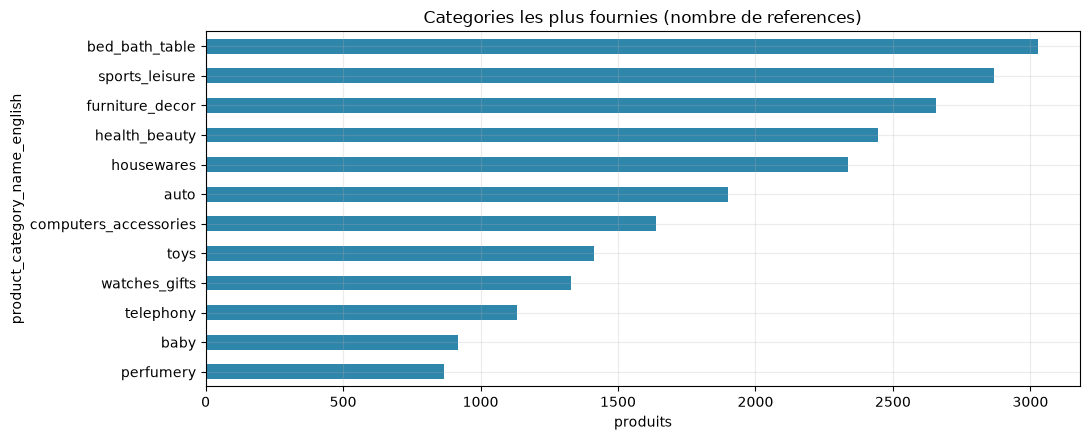

In [9]:
# Combien de categories, et sont-elles equilibrees ?
traduction = tables["translation"]
cat = produits.merge(traduction, on="product_category_name", how="left")
print("Categories distinctes :", cat["product_category_name_english"].nunique())
print()
top = cat["product_category_name_english"].value_counts().head(12)
top.plot(kind="barh", color="#2E86AB")
plt.gca().invert_yaxis()
plt.title("Categories les plus fournies (nombre de references)")
plt.xlabel("produits")
plt.tight_layout()
plt.show()

## Ce que ce notebook établit

| Point | Verdict |
|---|---|
| Quantité observable | ✅ par comptage de lignes de commande |
| Prix observable et variable | ✅ prix payé, distribution log-normale |
| Granularité produit × semaine | ❌ trop creuse (la plupart des produits < 10 ventes) |
| Fenêtre exploitable | 2017-01 → 2018-08 (les bords sont tronqués) |
| Nettoyage retenu | commandes livrées uniquement, écrêtage à 99.5 % |

**Suite :** notebook 02, où se joue la vraie décision — le grain d'agrégation,
qui détermine si une élasticité est identifiable ou non.